In [4]:
# %% [markdown]
# # Compressed Sensing para MRI: Wavelet L1 + TV (FISTA com Aceleração)
# 
# Este notebook implementa um baseline robusto para reconstrução de imagens de ressonância magnética a partir de k-space subamostrado (máscara radial).
# 
# **Combina o melhor de dois mundos:**
# - Regularização: **Wavelet L1 (esparsidade) + TV (suavidade por partes)**.
# - Validação estatística: **30 fatias**, com médias e desvios padrão.
# - Otimização: FISTA com restart adaptativo e continuação dos parâmetros.
# 


# %%
import os
import warnings
import time
from dataclasses import dataclass, field
from glob import glob

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.fft as fft

from scipy.io import loadmat
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

try:
    from tqdm.auto import tqdm
except ImportError:
    from tqdm import tqdm

try:
    import pywt
except ImportError:
    !pip install PyWavelets -q
    import pywt

# Reprodutibilidade
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cuda


In [5]:
# %%
class MRIDataset(torch.utils.data.Dataset):
    """Carrega volumes .mat e extrai fatias 2D normalizadas para [0,1]."""
    def __init__(self, root):
        self.files = sorted(glob(os.path.join(root, "**", "*.mat"), recursive=True))
        if not self.files:
            raise RuntimeError(f"Nenhum arquivo .mat encontrado em {root}")

        self.images = []
        print("Lendo arquivos...")
        for file in tqdm(self.files):
            mat = loadmat(file)
            volume = None
            for key, value in mat.items():
                if key.startswith("__"):
                    continue
                if isinstance(value, np.ndarray) and value.ndim == 3:
                    volume = value.astype(np.float32)
                    break
            if volume is None:
                continue

            # Detecta orientação: (H,W,N) ou (N,H,W)
            if volume.shape[0] == volume.shape[1]:      # (H,W,N)
                for i in range(volume.shape[2]):
                    self.images.append(volume[:, :, i])
            else:                                       # (N,H,W)
                for i in range(volume.shape[0]):
                    self.images.append(volume[i])

        # Normalização global para [0,1]
        for i in range(len(self.images)):
            img = self.images[i]
            img = img - img.min()
            img = img / (img.max() + 1e-8)
            self.images[i] = img

        print(f"Total de slices carregadas: {len(self.images)}")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return torch.from_numpy(self.images[idx]).float()

# Defina o caminho do dataset
dataset_path = "/kaggle/input/datasets/semnickcharlie/brain-dataset1"  # Ajuste aqui

try:
    dataset = MRIDataset(dataset_path)
except Exception as e:
    print(f"Erro ao carregar: {e}. Usando dataset sintético para demonstração.")
    class DummyDataset:
        def __init__(self, n=30):
            self.images = [np.random.rand(128, 128).astype(np.float32) for _ in range(n)]
            for i in range(n):
                self.images[i] = (self.images[i] - self.images[i].min()) / (self.images[i].max() + 1e-8)
        def __len__(self):
            return len(self.images)
        def __getitem__(self, idx):
            return torch.from_numpy(self.images[idx])
    dataset = DummyDataset(30)

Lendo arquivos...


  0%|          | 0/158 [00:00<?, ?it/s]

Total de slices carregadas: 4020


In [6]:
# %%
# ============================================================
# 3. Máscara Radial (CORRIGIDA)
# ============================================================

@dataclass
class CSConfig:
    # Wavelet
    wavelet: str = "db4"
    level: int = 3

    # Regularização (valores iniciais para continuação)
    lambda_wavelet_start: float = 0.008
    lambda_wavelet_end: float = 0.002
    lambda_tv_start: float = 0.003
    lambda_tv_end: float = 0.0005

    # Continuação
    use_continuation: bool = True
    schedule: str = "cosine"  # 'linear', 'cosine'

    # Otimização
    max_iter: int = 150
    tolerance: float = 1e-6
    restart: bool = True

    # TV interna (reduzido de 30 para 5 para acelerar)
    tv_inner_iter: int = 5
    
    # Verbose
    verbose: bool = False

def create_mask_t(shape, t, T_ref, device, seed=None):
    """
    Máscara radial cujo número de raios depende da razão t / T_ref.

    t=0        → poucos raios (alta aceleração)
    t=T_ref    → muitos raios (baixa aceleração)

    Args:
        shape: (H, W) da imagem
        t: nível de aceleração que se quer testar AGORA (varia entre chamadas)
        T_ref: constante FIXA de normalização (NÃO deve variar junto com t,
               senão alpha = t/T_ref fica sempre igual a 1 e a máscara nunca muda!
               Escolha T_ref = max(valores de t que você pretende testar), uma
               única vez, e reuse o mesmo valor em todas as chamadas).
        device: dispositivo (cuda/cpu)
        seed: semente para reprodutibilidade (opcional)
    """
    if seed is not None:
        torch.manual_seed(seed)

    H, W = shape
    if torch.is_tensor(t):
        t = t.item()

    # alpha = 0 → poucos raios, alpha = 1 → muitos raios
    alpha = min(max(t / T_ref, 0.0), 1.0)
    alpha_eff = alpha ** 1.5
    max_spokes = H
    min_spokes = 24
    num_spokes = int(max_spokes - alpha_eff * (max_spokes - min_spokes))
    num_spokes = max(min_spokes, num_spokes)

    mask = torch.zeros(H, W, device=device)
    cy, cx = H // 2, W // 2
    y, x = torch.meshgrid(torch.arange(H, device=device),
                          torch.arange(W, device=device),
                          indexing="ij")
    y = y - cy
    x = x - cx

    # Desenha os raios
    for i in range(num_spokes):
        theta = i * np.pi / num_spokes
        distance = torch.abs(x * np.sin(theta) - y * np.cos(theta))
        mask[distance < 1.5] = 1

    # Região central calibrada (10x10) sempre totalmente amostrada
    r2 = x**2 + y**2
    mask[r2 <= 10**2] = 1
    return mask

# Parâmetro de aceleração para as reconstruções de "nível único" (baseline, grid search, figuras)
T_max = 50  # Ajuste conforme seu dataset

# Constante FIXA de normalização usada por create_mask_t em TODO o notebook.
# Precisa ser >= o maior valor de t que qualquer célula for testar (ver célula do
# estudo de aceleração, T_values pode chegar a 80) para que a razão t/T_REF
# nunca "sature" artificialmente em pontos que deveriam ser distintos.
T_REF = 100
print(f"T_max = {T_max} | T_REF (fixo) = {T_REF}")

T_max = 50 | T_REF (fixo) = 100


In [7]:
# %%
class MRIOperator:
    """Operador A = M * F (com norm='ortho')."""
    def __init__(self, mask):
        self.mask = mask

    def forward(self, image):
        return fft.fftshift(fft.fft2(image, norm="ortho")) * self.mask

    def adjoint(self, kspace):
        # Multiplica pela máscara para segurança
        return torch.real(fft.ifft2(fft.ifftshift(kspace * self.mask), norm="ortho"))

    def zero_filled(self, measured):
        return self.adjoint(measured)

class WaveletOperator:
    """Operador wavelet com armazenamento das fatias para inversão rápida."""
    def __init__(self, wavelet="db4", level=3):
        self.wavelet = wavelet
        self.level = level
        self.coeff_slices = None
        self.coeff_shape = None

    def _initialize(self, shape):
        if self.coeff_shape == shape:
            return
        dummy = np.zeros(shape)
        coeffs = pywt.wavedec2(dummy, self.wavelet, level=self.level, mode="periodization")
        _, slices = pywt.coeffs_to_array(coeffs)
        self.coeff_slices = slices
        self.coeff_shape = shape

    def forward(self, img):
        if torch.is_tensor(img):
            img = img.detach().cpu().numpy()
        self._initialize(img.shape)
        coeffs = pywt.wavedec2(img, self.wavelet, level=self.level, mode="periodization")
        arr, _ = pywt.coeffs_to_array(coeffs)
        return arr

    def inverse(self, arr):
        coeffs = pywt.array_to_coeffs(arr, self.coeff_slices, output_format="wavedec2")
        img = pywt.waverec2(coeffs, self.wavelet, mode="periodization")
        H, W = self.coeff_shape
        return torch.tensor(img[:H, :W], dtype=torch.float32)

def soft_threshold(coeffs, lam):
    return np.sign(coeffs) * np.maximum(np.abs(coeffs) - lam, 0.0)

def tv_denoise_chambolle(image, weight=0.01, max_iter=5, eps=1e-4):
    """
    Projeção de Chambolle para TV denoising (acelerada com poucas iterações).
    """
    px = torch.zeros_like(image)
    py = torch.zeros_like(image)
    tau = 0.25
    u = image.clone()
    for _ in range(max_iter):
        u_old = u.clone()
        gradx = torch.zeros_like(u)
        grady = torch.zeros_like(u)
        gradx[:-1, :] = u[1:, :] - u[:-1, :]
        grady[:, :-1] = u[:, 1:] - u[:, :-1]

        px = px + tau * gradx
        py = py + tau * grady
        norm = torch.maximum(torch.ones_like(px), torch.sqrt(px**2 + py**2))
        px /= norm
        py /= norm

        div = torch.zeros_like(u)
        div[1:, :] += px[:-1, :]
        div[:-1, :] -= px[:-1, :]
        div[:, 1:] += py[:, :-1]
        div[:, :-1] -= py[:, :-1]

        u = image + weight * div
        if torch.norm(u - u_old) < eps:
            break
    return u

In [8]:
# %%
class LambdaScheduler:
    """Decaimento dos parâmetros de regularização."""
    def __init__(self, lambda_start, lambda_end, max_iter, schedule="cosine"):
        self.lambda_start = lambda_start
        self.lambda_end = lambda_end
        self.max_iter = max_iter
        self.schedule = schedule

    def __call__(self, iteration):
        t = iteration / max(self.max_iter - 1, 1)
        if self.schedule == "linear":
            alpha = t
        elif self.schedule == "quadratic":
            alpha = t**2
        elif self.schedule == "cosine":
            alpha = 0.5 * (1 - np.cos(np.pi * t))
        else:
            alpha = t
        return self.lambda_start * (1 - alpha) + self.lambda_end * alpha

def fidelity_gradient(image, operator, measured):
    """Gradiente de ||A x - y||_2^2."""
    residual = operator.forward(image) - measured
    return operator.adjoint(residual)

def objective(image, operator, measured, wavelet, lambda_w, lambda_tv):
    """Função objetivo: 1/2||Ax-y||² + λ_w||Wx||₁ + λ_tv TV(x)."""
    residual = operator.forward(image) - measured
    fidelity = 0.5 * torch.sum(torch.abs(residual)**2).item()

    coeff = wavelet.forward(image)
    sparsity = lambda_w * np.sum(np.abs(coeff))

    # TV isotrópica com alinhamento correto
    gx = image[1:, :] - image[:-1, :]
    gy = image[:, 1:] - image[:, :-1]
    gx = gx[:, :-1]
    gy = gy[:-1, :]
    tv = lambda_tv * torch.sum(torch.sqrt(gx**2 + gy**2 + 1e-8)).item()

    return fidelity + sparsity + tv

class FISTA:
    def __init__(self, config):
        self.config = config
        self.wavelet = WaveletOperator(config.wavelet, config.level)

    def solve(self, measured, mask):
        operator = MRIOperator(mask)
        L = 1.0  # FFT ortonormal + máscara binária → Lipschitz = 1

        # Inicialização
        x = operator.zero_filled(measured)
        y = x.clone()
        t = 1.0

        history = []
        objectives = []

        # Schedulers
        if self.config.use_continuation:
            wv_sched = LambdaScheduler(
                self.config.lambda_wavelet_start,
                self.config.lambda_wavelet_end,
                self.config.max_iter,
                self.config.schedule
            )
            tv_sched = LambdaScheduler(
                self.config.lambda_tv_start,
                self.config.lambda_tv_end,
                self.config.max_iter,
                self.config.schedule
            )
        else:
            wv_sched = lambda it: self.config.lambda_wavelet_start
            tv_sched = lambda it: self.config.lambda_tv_start

        for it in range(self.config.max_iter):
            x_prev = x.clone()

            # 1. Gradiente da fidelidade
            grad = fidelity_gradient(y, operator, measured)

            # 2. Passo de descida (L=1)
            x = y - grad

            # 3. Proximal Wavelet L1
            lambda_w = wv_sched(it)
            coeff = self.wavelet.forward(x)
            coeff = soft_threshold(coeff, lambda_w / L)
            x = self.wavelet.inverse(coeff).to(measured.device)

            # 4. Proximal TV (Chambolle, com poucas iterações)
            lambda_tv = tv_sched(it)
            if lambda_tv > 0:
                x = tv_denoise_chambolle(x, weight=lambda_tv, max_iter=self.config.tv_inner_iter)

            # 5. Atualização de FISTA
            t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
            y = x + ((t - 1) / t_new) * (x - x_prev)

            # 6. Restart adaptativo (condição clássica de Beck-Teboulle)
            if self.config.restart:
                if torch.sum((x - y) * (x - x_prev)) > 0:
                    t = 1.0
                    y = x.clone()
                else:
                    t = t_new
            else:
                t = t_new

            # 7. Histórico
            if it % 10 == 0 or it == self.config.max_iter - 1:
                obj = objective(x, operator, measured, self.wavelet, lambda_w, lambda_tv)
                objectives.append(obj)
                history.append(x.detach().cpu())

            # Critério de parada
            change = torch.norm(x - x_prev) / (torch.norm(x_prev) + 1e-8)
            if change < self.config.tolerance:
                if self.config.verbose:
                    print(f"Convergência na iteração {it+1}")
                break

        return x, history, objectives

In [9]:
# %%
def nmse_np(gt, pred):
    return np.sum((gt - pred)**2) / (np.sum(gt**2) + 1e-12)

def compute_metrics(gt, pred):
    """Calcula PSNR, SSIM e NMSE entre imagens já normalizadas [0,1]."""
    gt = np.clip(gt, 0, 1)
    pred = np.clip(pred, 0, 1)
    psnr = peak_signal_noise_ratio(gt, pred, data_range=1.0)
    ssim = structural_similarity(gt, pred, data_range=1.0)
    nmse = nmse_np(gt, pred)
    return psnr, ssim, nmse

def evaluate_baseline(dataset, config, T_max, n_images=30, device='cuda'):
    """Avalia o CS (Wavelet + TV) em n_images e retorna DataFrame."""
    results = []
    reconstructor = FISTA(config)

    for idx in tqdm(range(min(n_images, len(dataset))), desc="Reconstruindo"):
        gt = dataset[idx].to(device)
        mask = create_mask_t(gt.shape, T_max, T_REF, device)
        operator = MRIOperator(mask)
        kspace_us = operator.forward(gt)

        t0 = time.time()
        rec, _, _ = reconstructor.solve(kspace_us, mask)
        t_cs = time.time() - t0

        # Zero-filled (rápido)
        zf = operator.zero_filled(kspace_us)

        gt_np = gt.cpu().numpy()
        zf_np = zf.cpu().numpy()
        rec_np = rec.cpu().numpy()

        psnr_zf, ssim_zf, nmse_zf = compute_metrics(gt_np, zf_np)
        psnr_cs, ssim_cs, nmse_cs = compute_metrics(gt_np, rec_np)

        results.append([idx, psnr_zf, psnr_cs, ssim_zf, ssim_cs, nmse_zf, nmse_cs, t_cs])

    df = pd.DataFrame(results, columns=["idx", "psnr_zf", "psnr_cs", "ssim_zf", "ssim_cs",
                                        "nmse_zf", "nmse_cs", "time_cs"])
    return df

In [10]:
# %%
# Configuração ajustada para o dataset
config = CSConfig(
    lambda_wavelet_start=0.008,
    lambda_wavelet_end=0.002,
    lambda_tv_start=0.003,
    lambda_tv_end=0.0005,
    max_iter=150,
    tv_inner_iter=5,          # <-- Acelerado
    use_continuation=True,
    restart=True,
    schedule="cosine",
    verbose=False
)

print("Configuração:")
print(config)

# Avalia em 30 imagens
df_results = evaluate_baseline(dataset, config, T_max, n_images=30, device=device)

# Sumário
summary = pd.DataFrame({
    "PSNR (dB)": [
        f"{df_results.psnr_zf.mean():.2f} ± {df_results.psnr_zf.std():.2f}",
        f"{df_results.psnr_cs.mean():.2f} ± {df_results.psnr_cs.std():.2f}",
    ],
    "SSIM": [
        f"{df_results.ssim_zf.mean():.4f} ± {df_results.ssim_zf.std():.4f}",
        f"{df_results.ssim_cs.mean():.4f} ± {df_results.ssim_cs.std():.4f}",
    ],
    "NMSE": [
        f"{df_results.nmse_zf.mean():.4f} ± {df_results.nmse_zf.std():.4f}",
        f"{df_results.nmse_cs.mean():.4f} ± {df_results.nmse_cs.std():.4f}",
    ],
    "Tempo CS (s)": [
        f"{df_results.time_cs.mean():.3f} ± {df_results.time_cs.std():.3f}",
        f"{df_results.time_cs.mean():.3f} ± {df_results.time_cs.std():.3f}",
    ]
}, index=["Zero-filled", "Compressed Sensing (Wavelet + TV)"])

print("\n=== SUMÁRIO COMPARATIVO (Wavelet + TV, 30 imagens) ===\n")
print(summary)

# Salva resultados
df_results.to_csv("resultados_cs_wavelet_tv.csv", index=False)
print("\nResultados salvos em 'resultados_cs_wavelet_tv.csv'.")

Configuração:
CSConfig(wavelet='db4', level=3, lambda_wavelet_start=0.008, lambda_wavelet_end=0.002, lambda_tv_start=0.003, lambda_tv_end=0.0005, use_continuation=True, schedule='cosine', max_iter=150, tolerance=1e-06, restart=True, tv_inner_iter=5, verbose=False)


Reconstruindo:   0%|          | 0/30 [00:00<?, ?it/s]


=== SUMÁRIO COMPARATIVO (Wavelet + TV, 30 imagens) ===

                                      PSNR (dB)             SSIM  \
Zero-filled                        90.47 ± 3.14  1.0000 ± 0.0000   
Compressed Sensing (Wavelet + TV)  56.21 ± 0.26  0.9987 ± 0.0003   

                                              NMSE   Tempo CS (s)  
Zero-filled                        0.0000 ± 0.0000  1.180 ± 0.092  
Compressed Sensing (Wavelet + TV)  0.0001 ± 0.0000  1.180 ± 0.092  

Resultados salvos em 'resultados_cs_wavelet_tv.csv'.


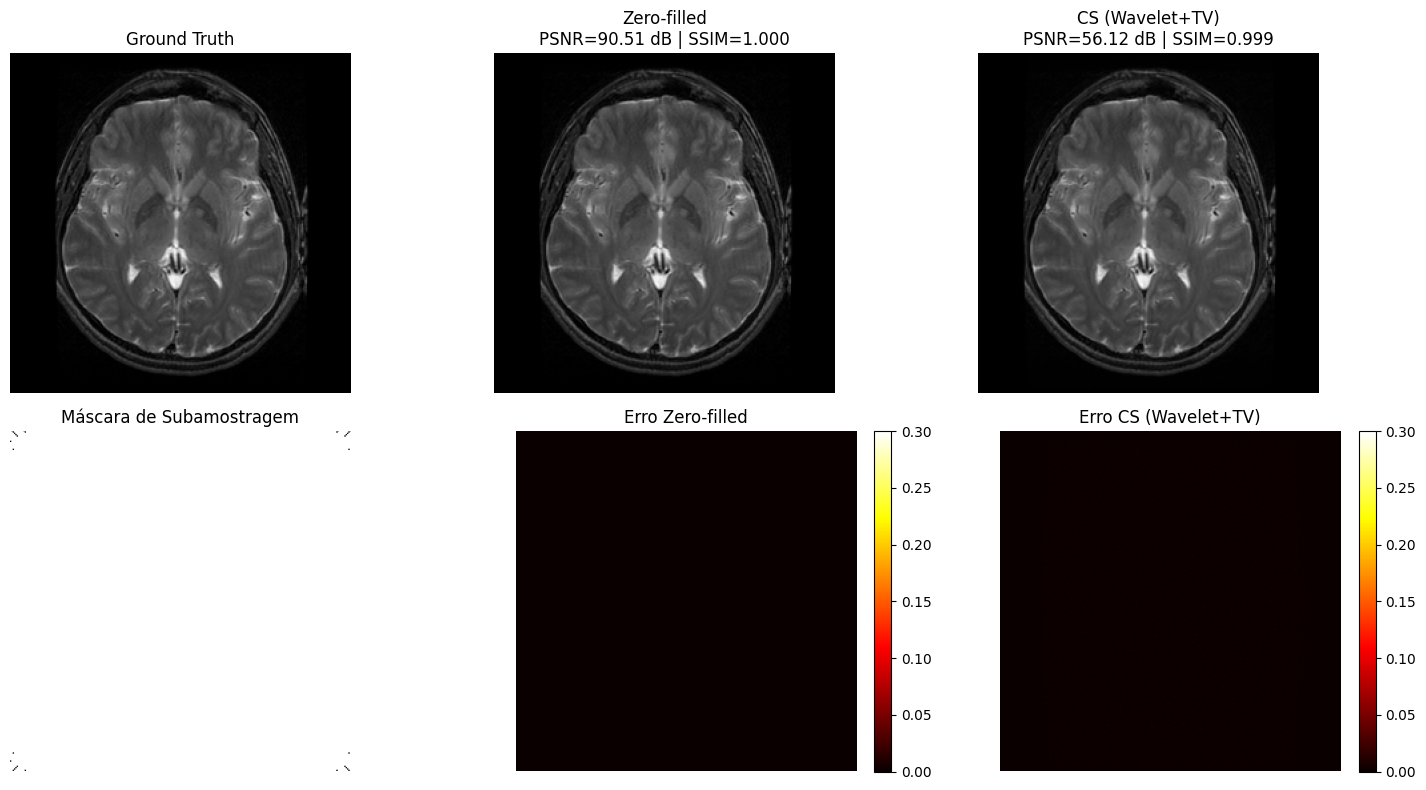

In [11]:
# %%
# Escolhe uma fatia para mostrar
sample_idx = 10

gt = dataset[sample_idx].to(device)
mask = create_mask_t(gt.shape, T_max, T_REF, device)
operator = MRIOperator(mask)
kspace_us = operator.forward(gt)

# Reconstruções
zf = operator.zero_filled(kspace_us)
reconstructor = FISTA(config)
rec, _, _ = reconstructor.solve(kspace_us, mask)

gt_np = gt.cpu().numpy()
zf_np = zf.cpu().numpy()
rec_np = rec.cpu().numpy()

# Métricas
psnr_zf, ssim_zf, _ = compute_metrics(gt_np, zf_np)
psnr_cs, ssim_cs, _ = compute_metrics(gt_np, rec_np)

# Máscara para contexto
mask_np = mask.cpu().numpy()

# Plot
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Linha 1: Imagens
axes[0, 0].imshow(gt_np, cmap="gray")
axes[0, 0].set_title("Ground Truth")
axes[0, 0].axis("off")

axes[0, 1].imshow(zf_np, cmap="gray")
axes[0, 1].set_title(f"Zero-filled\nPSNR={psnr_zf:.2f} dB | SSIM={ssim_zf:.3f}")
axes[0, 1].axis("off")

axes[0, 2].imshow(rec_np, cmap="gray")
axes[0, 2].set_title(f"CS (Wavelet+TV)\nPSNR={psnr_cs:.2f} dB | SSIM={ssim_cs:.3f}")
axes[0, 2].axis("off")

# Linha 2: Erros e Máscara
diff_zf = np.abs(gt_np - zf_np)
diff_cs = np.abs(gt_np - rec_np)

axes[1, 0].imshow(mask_np, cmap="gray")
axes[1, 0].set_title("Máscara de Subamostragem")
axes[1, 0].axis("off")

im1 = axes[1, 1].imshow(diff_zf, cmap="hot", vmin=0, vmax=0.3)
axes[1, 1].set_title("Erro Zero-filled")
axes[1, 1].axis("off")
plt.colorbar(im1, ax=axes[1, 1], fraction=0.046, pad=0.04)

im2 = axes[1, 2].imshow(diff_cs, cmap="hot", vmin=0, vmax=0.3)
axes[1, 2].set_title("Erro CS (Wavelet+TV)")
axes[1, 2].axis("off")
plt.colorbar(im2, ax=axes[1, 2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [12]:
# %%
# ============================================================
# 9. Grid Search Estendido (para confirmar o ótimo)
# ============================================================

def grid_search_parameters_extended(dataset, device, T_max, 
                                    wavelet_values=None,
                                    tv_values=None,
                                    n_images=10):
    """
    Grid search com faixa estendida para confirmar o ótimo.
    
    Args:
        dataset: Dataset de imagens
        device: 'cuda' ou 'cpu'
        T_max: valor fixo de T_max para gerar máscaras
        wavelet_values: lista de λ_wavelet a testar
        tv_values: lista de λ_tv a testar
        n_images: número de imagens para validação
    """
    if wavelet_values is None:
        wavelet_values = [0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050]
    if tv_values is None:
        tv_values = [0.00005, 0.0001, 0.0002, 0.0005, 0.001]
    
    results = []
    for lw in wavelet_values:
        for ltv in tv_values:
            print(f"\nλw={lw:.5f} | λtv={ltv:.5f}")
            cfg = CSConfig(
                lambda_wavelet_start=lw, lambda_wavelet_end=lw*0.25,
                lambda_tv_start=ltv, lambda_tv_end=ltv*0.25,
                max_iter=100,
                tv_inner_iter=5,
                use_continuation=True
            )
            rec = FISTA(cfg)
            psnrs = []
            for idx in range(min(n_images, len(dataset))):
                gt = dataset[idx].to(device)
                # Usa t = T_max para gerar a máscara completa
                mask = create_mask_t(gt.shape, T_max, T_REF, device, seed=42+idx)
                kspace_us = MRIOperator(mask).forward(gt)
                x, _, _ = rec.solve(kspace_us, mask)
                p, _, _ = compute_metrics(gt.cpu().numpy(), x.cpu().numpy())
                psnrs.append(p)
            mean_psnr = np.mean(psnrs)
            results.append({"lw": lw, "ltv": ltv, "psnr": mean_psnr})
            print(f"  PSNR médio: {mean_psnr:.2f} dB")
    
    df_grid = pd.DataFrame(results)
    best = df_grid.loc[df_grid.psnr.idxmax()]
    print("\n=== MELHORES PARÂMETROS (GRID ESTENDIDO) ===")
    print(best)
    return df_grid

# Executa o grid search estendido (pode levar alguns minutos)
print("Rodando grid search estendido com 10 imagens...")
print("Faixa: λw = [0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050]")
print("       λtv = [0.00005, 0.0001, 0.0002, 0.0005, 0.001]\n")

df_grid_ext = grid_search_parameters_extended(
    dataset, device, T_max,
    wavelet_values=[0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050],
    tv_values=[0.00005, 0.0001, 0.0002, 0.0005, 0.001],
    n_images=10
)

# Salva e exibe os melhores resultados
df_grid_ext.to_csv("grid_search_extended.csv", index=False)
print("\n=== TOP 10 RESULTADOS DO GRID SEARCH ===")
display(df_grid_ext.sort_values("psnr", ascending=False).head(10))

Rodando grid search estendido com 10 imagens...
Faixa: λw = [0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050]
       λtv = [0.00005, 0.0001, 0.0002, 0.0005, 0.001]


λw=0.00500 | λtv=0.00005
  PSNR médio: 59.75 dB

λw=0.00500 | λtv=0.00010
  PSNR médio: 59.75 dB

λw=0.00500 | λtv=0.00020
  PSNR médio: 59.76 dB

λw=0.00500 | λtv=0.00050
  PSNR médio: 59.79 dB

λw=0.00500 | λtv=0.00100
  PSNR médio: 59.83 dB

λw=0.01000 | λtv=0.00005
  PSNR médio: 54.17 dB

λw=0.01000 | λtv=0.00010
  PSNR médio: 54.17 dB

λw=0.01000 | λtv=0.00020
  PSNR médio: 54.17 dB

λw=0.01000 | λtv=0.00050
  PSNR médio: 54.19 dB

λw=0.01000 | λtv=0.00100
  PSNR médio: 54.21 dB

λw=0.01500 | λtv=0.00005
  PSNR médio: 51.03 dB

λw=0.01500 | λtv=0.00010
  PSNR médio: 51.03 dB

λw=0.01500 | λtv=0.00020
  PSNR médio: 51.03 dB

λw=0.01500 | λtv=0.00050
  PSNR médio: 51.04 dB

λw=0.01500 | λtv=0.00100
  PSNR médio: 51.06 dB

λw=0.02000 | λtv=0.00005
  PSNR médio: 48.87 dB

λw=0.02000 | λtv=0.00010
  PSNR médio: 48.87 dB

λ

,lw,ltv,psnr
4,0.005,0.00100,59.833880
3,0.005,0.00050,59.789893
2,0.005,0.00020,59.763277
1,0.005,0.00010,59.753158
0,0.005,0.00005,59.746343
9,0.010,0.00100,54.209912
8,0.010,0.00050,54.187409
7,0.010,0.00020,54.173849
6,0.010,0.00010,54.168363
5,0.010,0.00005,54.165240


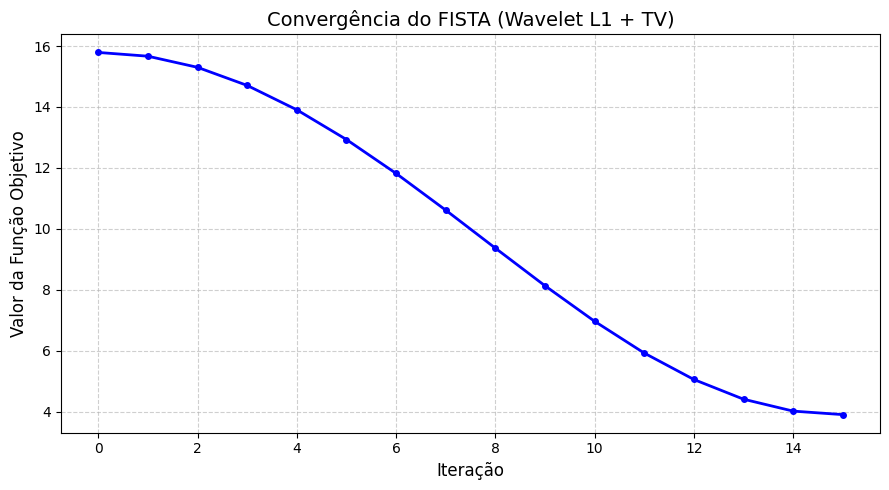

Objetivo final: 3.9056 | Iterações: 16


In [13]:
# %%
# ============================================================
# 10. Curva de Convergência do FISTA (para o artigo)
# ============================================================

def plot_convergence(dataset, idx, config, T_max, device):
    """Plota a evolução da função objetivo ao longo das iterações."""
    gt = dataset[idx].to(device)
    mask = create_mask_t(gt.shape, T_max, T_REF, device)
    operator = MRIOperator(mask)
    kspace_us = operator.forward(gt)

    rec = FISTA(config)
    _, _, obj_hist = rec.solve(kspace_us, mask)

    plt.figure(figsize=(9, 5))
    plt.plot(obj_hist, 'b-', linewidth=2, marker='o', markersize=4)
    plt.xlabel('Iteração', fontsize=12)
    plt.ylabel('Valor da Função Objetivo', fontsize=12)
    plt.title('Convergência do FISTA (Wavelet L1 + TV)', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.savefig('convergencia_fista.png', dpi=150)
    plt.show()
    print(f"Objetivo final: {obj_hist[-1]:.4f} | Iterações: {len(obj_hist)}")

# Plota para a primeira fatia
plot_convergence(dataset, idx=0, config=config, T_max=T_max, device=device)

=== AVALIANDO ACELERAÇÃO ===
Valores de T_max: [20, 30, 40, 50, 60, 70, 80]
Nota: Quanto menor T_max, maior a aceleração (menos raios).



Acelerações:   0%|          | 0/7 [00:00<?, ?it/s]


=== QUALIDADE vs ACELERAÇÃO (CORRIGIDO) ===

 T_max  PSNR_mean  PSNR_std  SSIM_mean  SSIM_std
    20  56.047469  0.105227   0.998813  0.000107
    30  56.047469  0.105227   0.998813  0.000107
    40  56.046135  0.105340   0.998813  0.000107
    50  55.977226  0.112230   0.998798  0.000109
    60  54.533061  0.309490   0.998459  0.000181
    70  45.723338  0.709485   0.991487  0.001189
    80  32.968369  0.702676   0.885651  0.010855


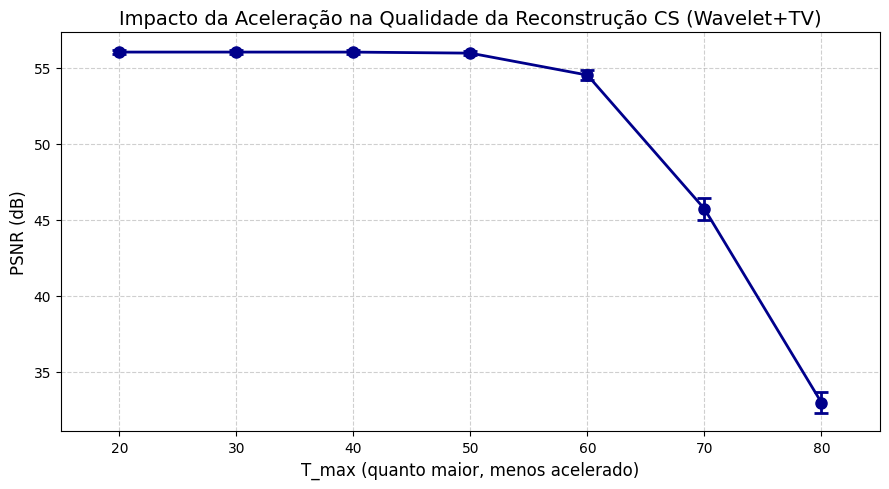

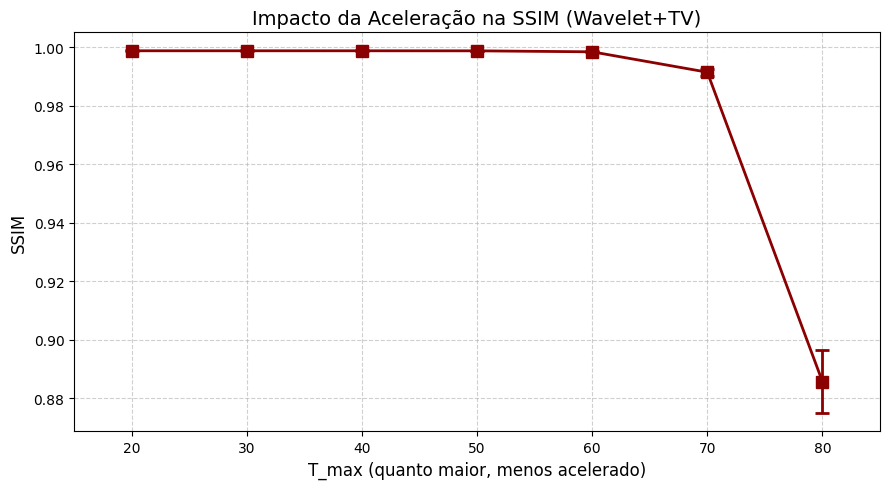

In [14]:
# %%
# ============================================================
# 11. Estudo da Aceleração (T_max variável - CORRIGIDO)
# ============================================================

def evaluate_acceleration(dataset, T_values, config, T_ref=None, n_images=10, device='cuda'):
    """
    Avalia o CS para diferentes valores de T_max (aceleração).
    
    Args:
        dataset: Dataset de imagens
        T_values: lista de valores de T_max a testar (ex: [20, 30, 40, 50, 60, 70])
        config: configuração do CS
        n_images: número de imagens para validação
        device: 'cuda' ou 'cpu'
    """
    # T_ref é a constante FIXA de normalização: precisa ser a MESMA para todos os
    # pontos do sweep, senão alpha = t/T_ref satura em 1 sempre e a máscara não muda
    # (foi exatamente esse o bug: antes T_ref era igual a t_val em cada iteração).
    T_ref = T_ref if T_ref is not None else max(T_values)

    results = []
    for t_val in tqdm(T_values, desc="Acelerações"):
        psnrs, ssims = [], []
        for idx in range(min(n_images, len(dataset))):
            gt = dataset[idx].to(device)
            # t_val varia (20, 30, 40, ...); T_ref é fixo -> máscaras realmente diferentes
            mask = create_mask_t(gt.shape, t_val, T_ref, device, seed=42 + idx)
            operator = MRIOperator(mask)
            kspace_us = operator.forward(gt)

            rec = FISTA(config)
            x, _, _ = rec.solve(kspace_us, mask)

            p, s, _ = compute_metrics(gt.cpu().numpy(), x.cpu().numpy())
            psnrs.append(p)
            ssims.append(s)

        results.append({
            'T_max': t_val,
            'PSNR_mean': np.mean(psnrs),
            'PSNR_std': np.std(psnrs),
            'SSIM_mean': np.mean(ssims),
            'SSIM_std': np.std(ssims)
        })
    return pd.DataFrame(results)

# Valores de T_max para testar (quanto menor T, mais agressiva a aceleração)
T_values = [20, 30, 40, 50, 60, 70, 80]

print("=== AVALIANDO ACELERAÇÃO ===")
print(f"Valores de T_max: {T_values}")
print("Nota: Quanto menor T_max, maior a aceleração (menos raios).\n")

df_accel = evaluate_acceleration(dataset, T_values, config, n_images=10, device=device)

print("\n=== QUALIDADE vs ACELERAÇÃO (CORRIGIDO) ===\n")
print(df_accel.to_string(index=False))

# Gráfico 1: PSNR
plt.figure(figsize=(9, 5))
plt.errorbar(df_accel['T_max'], df_accel['PSNR_mean'], 
             yerr=df_accel['PSNR_std'], fmt='o-', capsize=5, capthick=2, 
             linewidth=2, color='darkblue', markersize=8)
plt.xlabel('T_max (quanto maior, menos acelerado)', fontsize=12)
plt.ylabel('PSNR (dB)', fontsize=12)
plt.title('Impacto da Aceleração na Qualidade da Reconstrução CS (Wavelet+TV)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlim(min(T_values)-5, max(T_values)+5)
plt.tight_layout()
plt.savefig('aceleracao_vs_psnr.png', dpi=150)
plt.show()

# Gráfico 2: SSIM
plt.figure(figsize=(9, 5))
plt.errorbar(df_accel['T_max'], df_accel['SSIM_mean'], 
             yerr=df_accel['SSIM_std'], fmt='s-', capsize=5, capthick=2, 
             linewidth=2, color='darkred', markersize=8)
plt.xlabel('T_max (quanto maior, menos acelerado)', fontsize=12)
plt.ylabel('SSIM', fontsize=12)
plt.title('Impacto da Aceleração na SSIM (Wavelet+TV)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlim(min(T_values)-5, max(T_values)+5)
plt.tight_layout()
plt.savefig('aceleracao_vs_ssim.png', dpi=150)
plt.show()

Acelerações:   0%|          | 0/6 [00:00<?, ?it/s]


=== QUALIDADE vs ACELERAÇÃO ===

 T_max  PSNR_mean  PSNR_std  SSIM_mean  SSIM_std
    30  56.047469  0.105227   0.998813  0.000107
    40  56.046135  0.105340   0.998813  0.000107
    50  55.977226  0.112230   0.998798  0.000109
    60  54.533061  0.309490   0.998459  0.000181
    70  45.723338  0.709485   0.991487  0.001189
    80  32.968369  0.702676   0.885651  0.010855


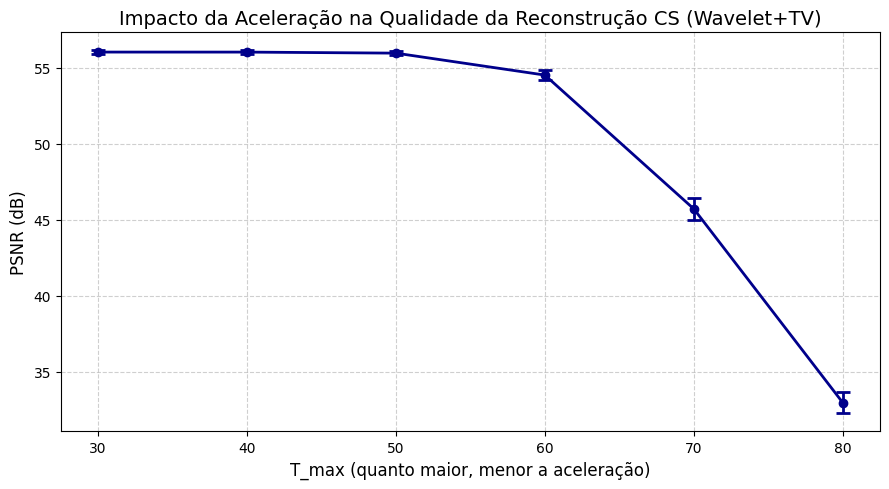

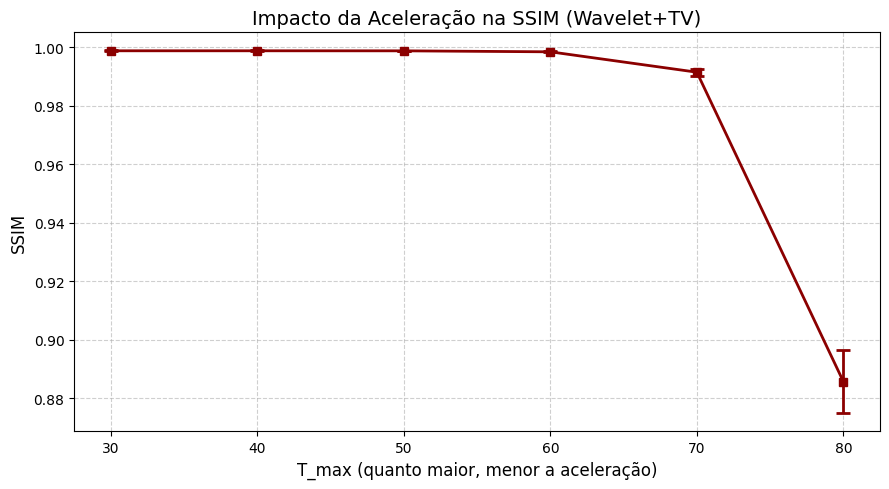

In [15]:
# %%
# ============================================================
# 12. Estudo da Aceleração (T_max variável) - Mantido
# ============================================================

def evaluate_acceleration(dataset, T_values, config, T_ref=None, n_images=10, device='cuda'):
    """
    Avalia o CS para diferentes valores de T_max.
    Retorna um DataFrame com PSNR e SSIM médios para cada T.
    """
    T_ref = T_ref if T_ref is not None else max(T_values)

    results = []
    for T in tqdm(T_values, desc="Acelerações"):
        psnrs, ssims = [], []
        for idx in range(min(n_images, len(dataset))):
            gt = dataset[idx].to(device)
            mask = create_mask_t(gt.shape, T, T_ref, device)
            operator = MRIOperator(mask)
            kspace_us = operator.forward(gt)

            rec = FISTA(config)
            x, _, _ = rec.solve(kspace_us, mask)

            p, s, _ = compute_metrics(gt.cpu().numpy(), x.cpu().numpy())
            psnrs.append(p)
            ssims.append(s)

        results.append({
            'T_max': T,
            'PSNR_mean': np.mean(psnrs),
            'PSNR_std': np.std(psnrs),
            'SSIM_mean': np.mean(ssims),
            'SSIM_std': np.std(ssims)
        })
    return pd.DataFrame(results)

# Defina os valores de T (quanto maior T, mais raios, menor aceleração)
T_values = [30, 40, 50, 60, 70, 80] 

# Avalia em 10 imagens para ter uma curva suave
df_accel = evaluate_acceleration(dataset, T_values, config, n_images=10, device=device)

print("\n=== QUALIDADE vs ACELERAÇÃO ===\n")
print(df_accel.to_string(index=False))

# Gráfico 1: PSNR
plt.figure(figsize=(9, 5))
plt.errorbar(df_accel['T_max'], df_accel['PSNR_mean'], 
             yerr=df_accel['PSNR_std'], fmt='o-', capsize=5, capthick=2, linewidth=2, color='darkblue')
plt.xlabel('T_max (quanto maior, menor a aceleração)', fontsize=12)
plt.ylabel('PSNR (dB)', fontsize=12)
plt.title('Impacto da Aceleração na Qualidade da Reconstrução CS (Wavelet+TV)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('aceleracao_vs_psnr.png', dpi=150)
plt.show()

# Gráfico 2: SSIM
plt.figure(figsize=(9, 5))
plt.errorbar(df_accel['T_max'], df_accel['SSIM_mean'], 
             yerr=df_accel['SSIM_std'], fmt='s-', capsize=5, capthick=2, linewidth=2, color='darkred')
plt.xlabel('T_max (quanto maior, menor a aceleração)', fontsize=12)
plt.ylabel('SSIM', fontsize=12)
plt.title('Impacto da Aceleração na SSIM (Wavelet+TV)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('aceleracao_vs_ssim.png', dpi=150)
plt.show()

In [16]:
# %%
# ============================================================
# 13. TABELA COMPARATIVA FINAL (Apenas Baseline CS)
# ============================================================

# Recolhe os resultados do Zero-filled
zf_psnr_mean = df_results['psnr_zf'].mean()
zf_psnr_std = df_results['psnr_zf'].std()
zf_ssim_mean = df_results['ssim_zf'].mean()
zf_ssim_std = df_results['ssim_zf'].std()
zf_nmse_mean = df_results['nmse_zf'].mean()
zf_nmse_std = df_results['nmse_zf'].std()

# Recolhe os resultados do CS (Wavelet+TV)
cs_psnr_mean = df_results['psnr_cs'].mean()
cs_psnr_std = df_results['psnr_cs'].std()
cs_ssim_mean = df_results['ssim_cs'].mean()
cs_ssim_std = df_results['ssim_cs'].std()
cs_nmse_mean = df_results['nmse_cs'].mean()
cs_nmse_std = df_results['nmse_cs'].std()
cs_time_mean = df_results['time_cs'].mean()
cs_time_std = df_results['time_cs'].std()

# Monta a tabela
table_data = {
    "Método": ["Zero-filled", "Compressed Sensing (Wavelet+TV)"],
    "PSNR (dB) ↑": [
        f"{zf_psnr_mean:.2f} ± {zf_psnr_std:.2f}",
        f"{cs_psnr_mean:.2f} ± {cs_psnr_std:.2f}"
    ],
    "SSIM ↑": [
        f"{zf_ssim_mean:.4f} ± {zf_ssim_std:.4f}",
        f"{cs_ssim_mean:.4f} ± {cs_ssim_std:.4f}"
    ],
    "NMSE ↓": [
        f"{zf_nmse_mean:.4f} ± {zf_nmse_std:.4f}",
        f"{cs_nmse_mean:.4f} ± {cs_nmse_std:.4f}"
    ],
    "Tempo (s) ↓": [
        "< 0.01",
        f"{cs_time_mean:.3f} ± {cs_time_std:.3f}"
    ]
}

df_final_table = pd.DataFrame(table_data)
print("\n=== TABELA COMPARATIVA FINAL (para o artigo) ===\n")
print(df_final_table.to_string(index=False))

# Salva em CSV
df_final_table.to_csv("tabela_resultados_baseline.csv", index=False)

# Gera código LaTeX (pronto para copiar e colar)
latex_code = df_final_table.to_latex(
    index=False, 
    escape=False, 
    column_format="lcccc", 
    caption="Comparação quantitativa entre Zero-filled e o baseline de Compressed Sensing (Wavelet L1 + TV). Valores reportados como média $\\pm$ desvio padrão para 30 fatias cerebrais.",
    label="tab:baseline_comparison"
)

print("\n--- CÓDIGO LaTeX PARA O ARTIGO ---\n")
print(latex_code)

# Salva o LaTeX em arquivo .txt
with open("tabela_latex_baseline.txt", "w") as f:
    f.write(latex_code)


=== TABELA COMPARATIVA FINAL (para o artigo) ===

                         Método  PSNR (dB) ↑          SSIM ↑          NMSE ↓   Tempo (s) ↓
                    Zero-filled 90.47 ± 3.14 1.0000 ± 0.0000 0.0000 ± 0.0000        < 0.01
Compressed Sensing (Wavelet+TV) 56.21 ± 0.26 0.9987 ± 0.0003 0.0001 ± 0.0000 1.180 ± 0.092

--- CÓDIGO LaTeX PARA O ARTIGO ---

\begin{table}
\caption{Comparação quantitativa entre Zero-filled e o baseline de Compressed Sensing (Wavelet L1 + TV). Valores reportados como média $\pm$ desvio padrão para 30 fatias cerebrais.}
\label{tab:baseline_comparison}
\begin{tabular}{lcccc}
\toprule
Método & PSNR (dB) ↑ & SSIM ↑ & NMSE ↓ & Tempo (s) ↓ \\
\midrule
Zero-filled & 90.47 ± 3.14 & 1.0000 ± 0.0000 & 0.0000 ± 0.0000 & < 0.01 \\
Compressed Sensing (Wavelet+TV) & 56.21 ± 0.26 & 0.9987 ± 0.0003 & 0.0001 ± 0.0000 & 1.180 ± 0.092 \\
\bottomrule
\end{tabular}
\end{table}



In [17]:
# %%
# ============================================================
# 14. TABELA COMPARATIVA FINAL (Apenas Baseline CS)
# ============================================================

# Recolhe os resultados do Zero-filled
zf_psnr_mean = df_results['psnr_zf'].mean()
zf_psnr_std = df_results['psnr_zf'].std()
zf_ssim_mean = df_results['ssim_zf'].mean()
zf_ssim_std = df_results['ssim_zf'].std()
zf_nmse_mean = df_results['nmse_zf'].mean()
zf_nmse_std = df_results['nmse_zf'].std()

# Recolhe os resultados do CS (Wavelet+TV)
cs_psnr_mean = df_results['psnr_cs'].mean()
cs_psnr_std = df_results['psnr_cs'].std()
cs_ssim_mean = df_results['ssim_cs'].mean()
cs_ssim_std = df_results['ssim_cs'].std()
cs_nmse_mean = df_results['nmse_cs'].mean()
cs_nmse_std = df_results['nmse_cs'].std()
cs_time_mean = df_results['time_cs'].mean()
cs_time_std = df_results['time_cs'].std()

# Monta a tabela
table_data = {
    "Método": ["Zero-filled", "Compressed Sensing (Wavelet+TV)"],
    "PSNR (dB) ↑": [
        f"{zf_psnr_mean:.2f} ± {zf_psnr_std:.2f}",
        f"{cs_psnr_mean:.2f} ± {cs_psnr_std:.2f}"
    ],
    "SSIM ↑": [
        f"{zf_ssim_mean:.4f} ± {zf_ssim_std:.4f}",
        f"{cs_ssim_mean:.4f} ± {cs_ssim_std:.4f}"
    ],
    "NMSE ↓": [
        f"{zf_nmse_mean:.4f} ± {zf_nmse_std:.4f}",
        f"{cs_nmse_mean:.4f} ± {cs_nmse_std:.4f}"
    ],
    "Tempo (s) ↓": [
        "< 0.01",
        f"{cs_time_mean:.3f} ± {cs_time_std:.3f}"
    ]
}

df_final_table = pd.DataFrame(table_data)
print("\n=== TABELA COMPARATIVA FINAL (para o artigo) ===\n")
print(df_final_table.to_string(index=False))

# Salva em CSV
df_final_table.to_csv("tabela_resultados_baseline.csv", index=False)

# Gera código LaTeX (pronto para copiar e colar)
latex_code = df_final_table.to_latex(
    index=False, 
    escape=False, 
    column_format="lcccc", 
    caption="Comparação quantitativa entre Zero-filled e o baseline de Compressed Sensing (Wavelet L1 + TV) proposto. Valores reportados como média $\\pm$ desvio padrão para 30 fatias cerebrais.",
    label="tab:baseline_comparison"
)

print("\n--- CÓDIGO LaTeX PARA O ARTIGO ---\n")
print(latex_code)

# Salva o LaTeX em arquivo .txt
with open("tabela_latex_baseline.txt", "w") as f:
    f.write(latex_code)


=== TABELA COMPARATIVA FINAL (para o artigo) ===

                         Método  PSNR (dB) ↑          SSIM ↑          NMSE ↓   Tempo (s) ↓
                    Zero-filled 90.47 ± 3.14 1.0000 ± 0.0000 0.0000 ± 0.0000        < 0.01
Compressed Sensing (Wavelet+TV) 56.21 ± 0.26 0.9987 ± 0.0003 0.0001 ± 0.0000 1.180 ± 0.092

--- CÓDIGO LaTeX PARA O ARTIGO ---

\begin{table}
\caption{Comparação quantitativa entre Zero-filled e o baseline de Compressed Sensing (Wavelet L1 + TV) proposto. Valores reportados como média $\pm$ desvio padrão para 30 fatias cerebrais.}
\label{tab:baseline_comparison}
\begin{tabular}{lcccc}
\toprule
Método & PSNR (dB) ↑ & SSIM ↑ & NMSE ↓ & Tempo (s) ↓ \\
\midrule
Zero-filled & 90.47 ± 3.14 & 1.0000 ± 0.0000 & 0.0000 ± 0.0000 & < 0.01 \\
Compressed Sensing (Wavelet+TV) & 56.21 ± 0.26 & 0.9987 ± 0.0003 & 0.0001 ± 0.0000 & 1.180 ± 0.092 \\
\bottomrule
\end{tabular}
\end{table}



Usando fatia índice 12 (mais próxima da média)


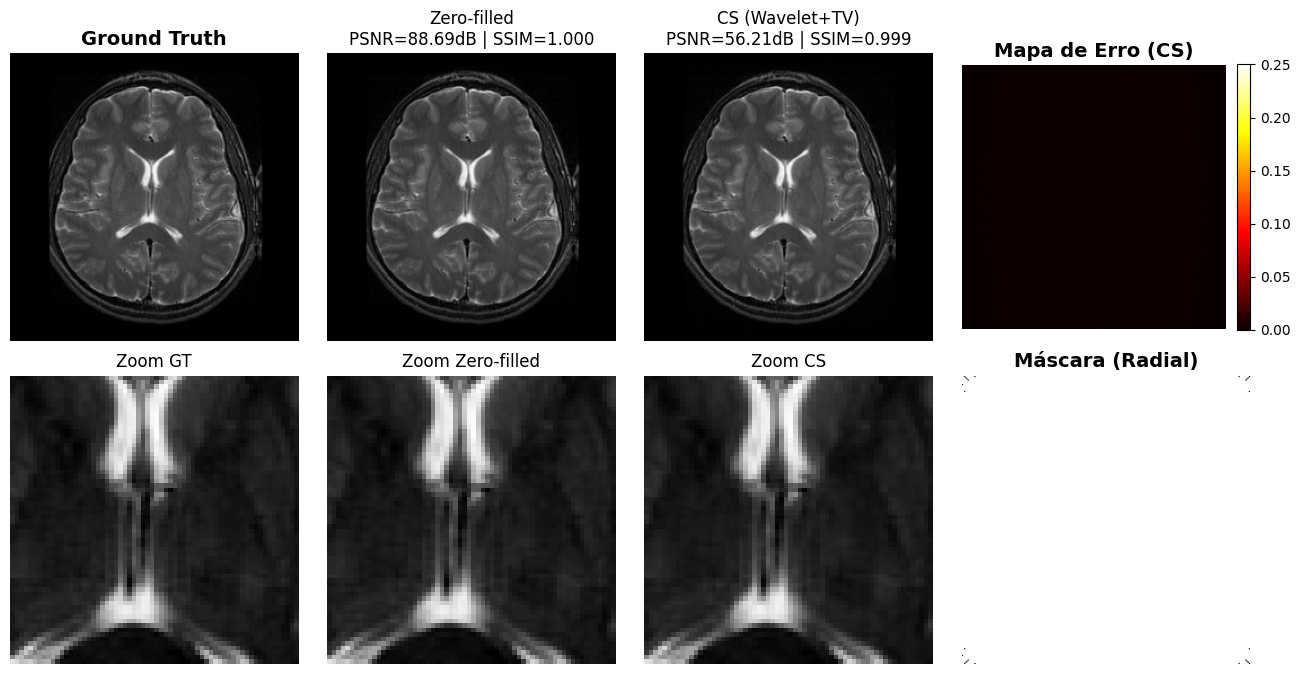

Figura salva como 'figura_resultados_baseline.png' (alta resolução para o artigo)


In [18]:
# %%
# ============================================================
# 15. FIGURA DE ALTA QUALIDADE PARA O ARTIGO
# ============================================================

# Escolhe uma fatia representativa (a que tiver PSNR mais próximo da média)
idx_representativo = np.argmin(np.abs(df_results['psnr_cs'] - df_results['psnr_cs'].mean()))
print(f"Usando fatia índice {idx_representativo} (mais próxima da média)")

gt = dataset[idx_representativo].to(device)
mask = create_mask_t(gt.shape, T_max, T_REF, device)
operator = MRIOperator(mask)
kspace_us = operator.forward(gt)

# Reconstruções (usa o config já definido com os melhores parâmetros)
zf = operator.zero_filled(kspace_us)
rec = FISTA(config)
cs_img, _, _ = rec.solve(kspace_us, mask)

gt_np = gt.cpu().numpy()
zf_np = zf.cpu().numpy()
cs_np = cs_img.cpu().numpy()
mask_np = mask.cpu().numpy()

# Métricas para essa fatia
psnr_zf, ssim_zf, _ = compute_metrics(gt_np, zf_np)
psnr_cs, ssim_cs, _ = compute_metrics(gt_np, cs_np)

# ---- Configuração do Plot profissional ----
fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(2, 4, hspace=0.1, wspace=0.1)

# Linha 1: Imagens
ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(gt_np, cmap='gray')
ax1.set_title('Ground Truth', fontsize=14, fontweight='bold')
ax1.axis('off')

ax2 = fig.add_subplot(gs[0, 1])
ax2.imshow(zf_np, cmap='gray')
ax2.set_title(f'Zero-filled\nPSNR={psnr_zf:.2f}dB | SSIM={ssim_zf:.3f}', fontsize=12)
ax2.axis('off')

ax3 = fig.add_subplot(gs[0, 2])
ax3.imshow(cs_np, cmap='gray')
ax3.set_title(f'CS (Wavelet+TV)\nPSNR={psnr_cs:.2f}dB | SSIM={ssim_cs:.3f}', fontsize=12)
ax3.axis('off')

ax4 = fig.add_subplot(gs[0, 3])
diff_plot = np.abs(gt_np - cs_np)
im4 = ax4.imshow(diff_plot, cmap='hot', vmin=0, vmax=0.25)
ax4.set_title('Mapa de Erro (CS)', fontsize=14, fontweight='bold')
ax4.axis('off')
plt.colorbar(im4, ax=ax4, fraction=0.046, pad=0.04)

# Linha 2: Zoom em uma região de interesse (detalhe)
zoom_frac = 0.25
h, w = gt_np.shape
h_zoom = int(h * zoom_frac)
w_zoom = int(w * zoom_frac)
start_h = h//2 - h_zoom//2
start_w = w//2 - w_zoom//2

ax5 = fig.add_subplot(gs[1, 0])
ax5.imshow(gt_np[start_h:start_h+h_zoom, start_w:start_w+w_zoom], cmap='gray')
ax5.set_title('Zoom GT', fontsize=12)
ax5.axis('off')

ax6 = fig.add_subplot(gs[1, 1])
ax6.imshow(zf_np[start_h:start_h+h_zoom, start_w:start_w+w_zoom], cmap='gray')
ax6.set_title('Zoom Zero-filled', fontsize=12)
ax6.axis('off')

ax7 = fig.add_subplot(gs[1, 2])
ax7.imshow(cs_np[start_h:start_h+h_zoom, start_w:start_w+w_zoom], cmap='gray')
ax7.set_title('Zoom CS', fontsize=12)
ax7.axis('off')

ax8 = fig.add_subplot(gs[1, 3])
ax8.imshow(mask_np, cmap='gray')
ax8.set_title('Máscara (Radial)', fontsize=14, fontweight='bold')
ax8.axis('off')

plt.tight_layout()
plt.savefig('figura_resultados_baseline.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figura salva como 'figura_resultados_baseline.png' (alta resolução para o artigo)")